In [ ]:
###Restartování simulací a pokračování v nich

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
from resources.Classes.Wave_function_class import *
from resources.Functions.system_fucntions import *
from matplotlib.colors import LogNorm
from resources.Classes.Simulation_Class import Simulation_Class
from resources.Classes.Wave_vector_class import Wave_vector_class
from resources.Classes.Nbody_classes.Baryonic_N_body import Baryons
from resources.Classes.Nbody_classes.NBodyGas import NBodyGas
from resources.Classes.Nbody_classes.Sink_N_Body import SinkNBody

In [2]:
import copy
import cupy as cp
import numpy as np


def _copy_value(v):
    """
    Deep-ish copy that handles CuPy arrays safely.
    """
    if isinstance(v, cp.ndarray):
        return v.copy()

    if isinstance(v, np.ndarray):
        return v.copy()

    if isinstance(v, list):
        return [_copy_value(x) for x in v]

    if isinstance(v, tuple):
        return tuple(_copy_value(x) for x in v)

    if isinstance(v, dict):
        return {k: _copy_value(val) for k, val in v.items()}

    try:
        return copy.deepcopy(v)
    except Exception:
        return v


def clone_component(obj, new_sim):
    """
    Copy arbitrary simulation component and reconnect it to new_sim.
    Works for Wave_function, Baryons, SinkNBody, NBodyGas, provided their state
    is stored in normal attributes.
    """
    cls = obj.__class__
    new = cls.__new__(cls)

    for key, value in obj.__dict__.items():
        setattr(new, key, _copy_value(value))

    if hasattr(new, "simulation"):
        new.simulation = new_sim

    return new


def wrap_positions_to_box(positions, boundaries):
    lows = cp.asarray([b[0] for b in boundaries], dtype=cp.float64)
    highs = cp.asarray([b[1] for b in boundaries], dtype=cp.float64)
    box = highs - lows
    return (positions - lows) % box + lows


def fourier_shift_field(field, sim, shift):
    """
    Periodic continuous shift of a scalar/grid field.

    Returns field(x - shift), i.e. the structure is moved by +shift.
    """
    shift = tuple(float(s) for s in shift)

    field_k = cp.fft.fftn(field)

    phase = cp.ones_like(field_k, dtype=cp.complex128)
    for k_axis, s in zip(sim.k_space, shift):
        phase *= cp.exp(-1j * k_axis * s)

    shifted = cp.fft.ifftn(field_k * phase)

    if cp.iscomplexobj(field):
        return shifted.astype(field.dtype, copy=False)
    else:
        return shifted.real.astype(field.dtype, copy=False)

In [3]:
import cupy as cp
import numpy as np


def add_bulk_velocity_to_component(comp, sim, velocity):
    """
    Add a uniform physical velocity to one component.

    velocity must be in simulation velocity units, i.e. kpc/Gyr.
    For particles/sinks: v -> v + velocity.
    For gas: vx, vy, vz -> vx, vy, vz + velocity components.
    For wave function: psi -> psi * exp(i v.x / hbar_tilde).
    """
    velocity = cp.asarray(velocity, dtype=cp.float64)

    # ULDM wave function
    if hasattr(comp, "psi"):
        phase_arg = cp.zeros_like(comp.psi, dtype=cp.float64)

        for ax in range(sim.dim):
            phase_arg += velocity[ax] * cp.asarray(sim.grids[ax])

        comp.psi = comp.psi * cp.exp(1j * phase_arg / sim.h_bar_tilde)
        return comp

    # Particle components: Baryons, SinkNBody
    if hasattr(comp, "velocities"):
        comp.velocities = cp.asarray(comp.velocities) + velocity[None, :]

    # Gas component
    if comp.__class__.__name__.lower() == "nbodygas":
        comp.vx = comp.vx + velocity[0]
        comp.vy = comp.vy + velocity[1]
        comp.vz = comp.vz + velocity[2]
        comp.vel = [comp.vx, comp.vy, comp.vz]

        if getattr(comp, "E", None) is not None:
            v2_old = (
                (comp.vx - velocity[0])**2
                + (comp.vy - velocity[1])**2
                + (comp.vz - velocity[2])**2
            )
            v2_new = comp.vx**2 + comp.vy**2 + comp.vz**2

            # Preserve internal energy and update only kinetic part of gas energy
            comp.E = comp.E - 0.5 * comp.rho * v2_old + 0.5 * comp.rho * v2_new

    return comp

In [4]:
def shift_component(comp, sim, shift):
    """
    Shift one cloned component by physical vector shift = (dx, dy, dz).
    """
    shift_arr = cp.asarray(shift, dtype=cp.float64)
    cls_name = comp.__class__.__name__.lower()

    # Wave function
    if hasattr(comp, "psi"):
        comp.psi = fourier_shift_field(comp.psi, sim, shift)

        if hasattr(comp, "means"):
            try:
                comp.means = [float(m) + float(s) for m, s in zip(comp.means, shift)]
            except Exception:
                pass

        return comp

    # Particle-like components: Baryons, SinkNBody
    if hasattr(comp, "positions"):
        comp.positions = cp.asarray(comp.positions) + shift_arr
        comp.positions = wrap_positions_to_box(comp.positions, sim.boundaries)

    # Grid gas
    if cls_name == "nbodygas":
        comp.rho = fourier_shift_field(comp.rho, sim, shift)
        comp.vx = fourier_shift_field(comp.vx, sim, shift)
        comp.vy = fourier_shift_field(comp.vy, sim, shift)
        comp.vz = fourier_shift_field(comp.vz, sim, shift)

        if getattr(comp, "E", None) is not None:
            comp.E = fourier_shift_field(comp.E, sim, shift)

        comp.vel = [comp.vx, comp.vy, comp.vz]

        # numerical safety, hlavně po Fourier shiftu plynu
        if hasattr(comp, "rho_floor"):
            comp.rho = cp.maximum(comp.rho, comp.rho_floor)

        if hasattr(comp, "e_floor") and comp.E is not None:
            comp.E = cp.maximum(comp.E, comp.e_floor)

    return comp

In [5]:
def duplicate_system_into_two_copies_with_velocity(
    sim,
    shift_a,
    shift_b,
    velocity_a=(0.0, 0.0, 0.0),
    velocity_b=(0.0, 0.0, 0.0),
):
    """
    Replace the current system by two shifted and boosted copies.
    """

    original_wave_functions = list(sim.wave_functions)
    original_baryons = list(sim.baryonic_matter)

    new_wave_functions = []
    new_baryonic_matter = []

    for shift, velocity in [(shift_a, velocity_a), (shift_b, velocity_b)]:

        for wf in original_wave_functions:
            wf_copy = clone_component(wf, sim)
            wf_copy = shift_component(wf_copy, sim, shift)
            wf_copy = add_bulk_velocity_to_component(wf_copy, sim, velocity)
            new_wave_functions.append(wf_copy)

        for comp in original_baryons:
            comp_copy = clone_component(comp, sim)
            comp_copy = shift_component(comp_copy, sim, shift)
            comp_copy = add_bulk_velocity_to_component(comp_copy, sim, velocity)
            new_baryonic_matter.append(comp_copy)

    sim.wave_functions = new_wave_functions
    sim.baryonic_matter = new_baryonic_matter
    sim.num_of_w_vects_in_sim = len(new_wave_functions)

    return sim

In [6]:
from resources.Functions.reuse_simulation_output import load_saved_state_into_sim,load_saved_state_into_larger_sim

In [16]:
boundaries = [[-25, 25], [-25, 25], [-25, 25]]
KM_S_TO_KPC_GYR = 1.0227121650537077
m_scalar_eV = 1e-22
sim = Simulation_Class(
    dim=3,
    boundaries=boundaries,
    N=128,
    total_time=20,
    h=2e-3,
    order_of_evolution=2,
    use_gravity=True,
    static_potential=None,
    save_max_vals=True,
    self_int=False,
    use_sponge=True,
    m_s=m_scalar_eV,
)

start_step, current_time = load_saved_state_into_larger_sim(
    sim,
    "resources/data/ULDM+MBH1e6",
)

# 2) nahradíš jeden systém dvěma kopiemi
dx = sim.dx[0]
shift = 51 * dx   # 19.921875 for [-50,50], N=256
print(shift/4)
sep_vec = np.array([shift, shift, 0.0])
u = sep_vec / np.linalg.norm(sep_vec)
t = np.array([-u[1], u[0], 0.0])

v_in_kms = 0.5
v_orb_kms = 0.75

v_in = v_in_kms * KM_S_TO_KPC_GYR
v_orb = v_orb_kms * KM_S_TO_KPC_GYR

velocity_a = -v_in * u + v_orb * t
velocity_b = +v_in * u - v_orb * t

duplicate_system_into_two_copies_with_velocity(
    sim,
    shift_a=(+shift/4, +shift/4, 0.0),
    shift_b=(-shift/4, -shift/4, 0.0),
    velocity_a=velocity_a,
    velocity_b=velocity_b,
)


hbartilde 19.60695038367394
passed mass is 1000000.0
dynamic mass 0.0
pracuji s len 1 functions: [<resources.Classes.Wave_function_class.Wave_function object at 0x7ffb2b84af10>]

Maximum allowed time step: 0.0016514631511592706
  - From dispersion relation: 0.003302926302318541
  - From potential term: 1231941025692.9924


Do you want to continue with the current time step anyway? (y/n):  y


Continuing with user-specified time step despite stability concerns.
4.98046875


In [17]:
print(sim.wave_functions)
print(sim.baryonic_matter)

[<resources.Classes.Wave_function_class.Wave_function object at 0x7ffb2b8aec90>, <resources.Classes.Wave_function_class.Wave_function object at 0x7ffb38c2c490>]
[<resources.Classes.Nbody_classes.Sink_N_Body.SinkNBody object at 0x7ffb2bdfd850>, <resources.Classes.Nbody_classes.Sink_N_Body.SinkNBody object at 0x7ffb2b848210>]


In [18]:
sim.initialize_simulation()

outdir = "resources/data/two_system_collision_solbh"

sim.snapshot_directory = outdir
sim.evolution.scribe.snapshot_directory = outdir

pracuji s len 2 functions: [<resources.Classes.Wave_function_class.Wave_function object at 0x7ffb2b8aec90>, <resources.Classes.Wave_function_class.Wave_function object at 0x7ffb38c2c490>]

Maximum allowed time step: 0.0016514631511592706
  - From dispersion relation: 0.003302926302318541
  - From potential term: 1231941025692.9924


Do you want to continue with the current time step anyway? (y/n):  y


Continuing with user-specified time step despite stability concerns.


Mass: 659729226.7564963
Deviation [%]: 559.7292267564964
[Energy gauge] sink potential reference set to phi_ref = 1.365676e-01
mass diff is 0.000000 Msun


Simulation Progress:   0%|          | 0/10000 [00:00<?, ?step/s]

starting evolution
is first


Simulation Progress: 100%|██████████| 10000/10000 [10:34<00:00, 15.75step/s]


is last
Energy log saved to: resources/data/two_system_collision_solbh/energy.txt
Saved sink debug log to resources/data/two_system_collision_solbh/sink_debug_log.csv
resources/data/max_values.csv saved


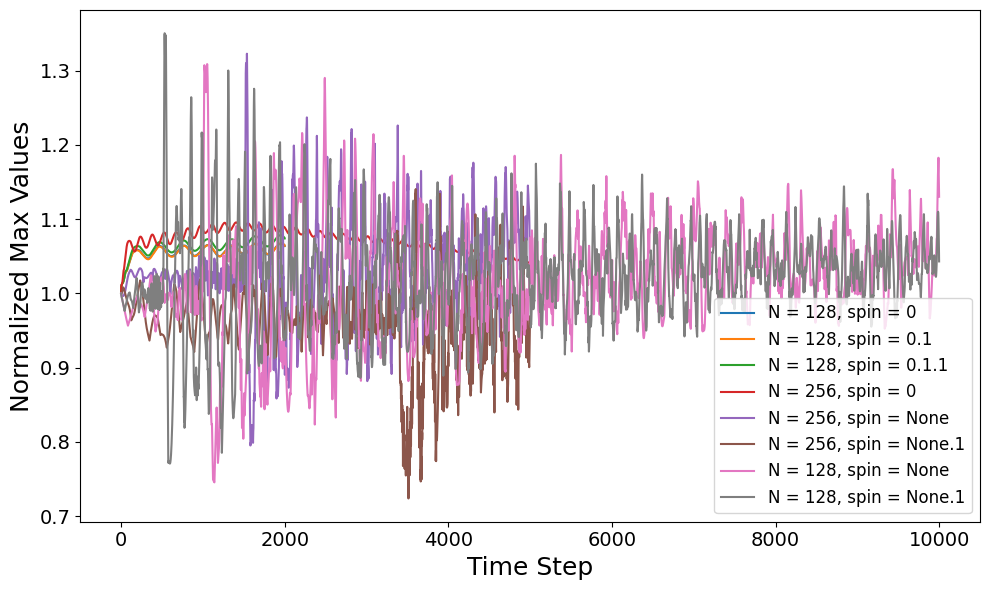

Evolution completed successfully
Saved times are [0, 0.002, 2.0020000000000002, 4.002, 6.002, 8.002, 10.002, 12.002, 14.002, 16.002, 18.002, 20]


In [19]:

# 4) buď pokračuješ od nuly v nové konfiguraci:
sim.evolve(save_every=1000, start_step=0)

In [1]:
import pandas as pd

# Load the original file
df = pd.read_csv('resources/data/max_values.csv')

# Extract the last column
last_col = df.iloc[:, -1].copy()

# Modify the first value
last_col.iloc[0] = 's=0'

# Create a new DataFrame with just this column, named as requested earlier
new_df = pd.DataFrame(last_col)
new_df.columns = ['N256']

# Save to CSV
output_filename = 'galaxy_max_vals.csv'
new_df.to_csv(output_filename, index=False)

print(f"File saved as {output_filename}")

File saved as galaxy_max_vals.csv


N256    1.548140e+08
Name: 0, dtype: float64


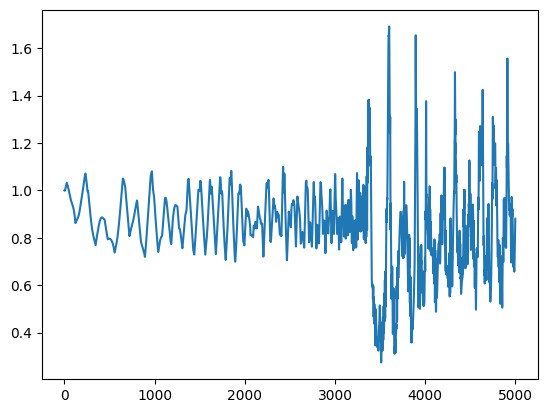

In [14]:
df = pd.read_csv('galaxy_max_vals.csv', skiprows=[1])

df = df/df.iloc[0]
df['N256'].plot()
plt.show()

Error in callback <function _draw_all_if_interactive at 0x7f7363fec860> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



Error in callback <function flush_figures at 0x7f7364003b00> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



SyntaxError: invalid syntax (3149637218.py, line 1)

In [21]:
import numpy as np
from pathlib import Path

path = Path("resources/data/two_system_orbit+collision/baryonic_component_2_NBodyGas_at_time_5.002000.npz")
gas = np.load(path, allow_pickle=True)

rho = gas["rho"]
vx = gas["vx"]
vy = gas["vy"]
vz = gas["vz"]
E = gas["E"]
E_radiated = gas["E_radiated"].item()

print("rho:", rho.shape, rho.min(), rho.max(), rho.mean())
print("vx:", vx.shape, vx.min(), vx.max(), vx.mean())
print("vy:", vy.shape, vy.min(), vy.max(), vy.mean())
print("vz:", vz.shape, vz.min(), vz.max(), vz.mean())
print("E:", E.shape, E.min(), E.max(), E.mean())
print("E_radiated:", E_radiated)

rho: (256, 256, 256) 5.1160235961958875 9185.94345325795 19.02157872013867
vx: (256, 256, 256) -41.71966113142816 70.14137240441819 -0.5013981278049793
vy: (256, 256, 256) -66.22569577315922 64.57821764346826 0.4491638552256789
vz: (256, 256, 256) -53.27956081663832 66.10414935355206 0.009554151744554897
E: (256, 256, 256) 5751.77724117684 19334653.0155026 18529.867348742035
E_radiated: 0.0


In [27]:
import numpy as np
from pathlib import Path

path = Path("resources/data/two_system_orbit+collision/baryonic_component_0_Baryons_at_time_5.002000.npz")
stars = np.load(path, allow_pickle=True)

positions = stars["positions"]      # shape: (N, 3)
velocities = stars["velocities"]    # shape: (N, 3)
m_particle = stars["m_particle"].item()
N = stars["N"].item()

print("N =", N)
print("m_particle =", m_particle)
print("total mass =", N * m_particle)

print("positions shape:", positions.shape)
print("velocities shape:", velocities.shape)

print("first 5 positions:")
print(positions[:5])

print("first 5 velocities:")
print(velocities[:5])

N = 1
m_particle = 30.0
total mass = 30.0
positions shape: (1, 3)
velocities shape: (1, 3)
first 5 positions:
[[ 2.41997198e+00  1.31560683e+01 -3.24463156e-04]]
first 5 velocities:
[[-2.1838262  -5.12017511 -0.01578959]]


In [28]:
import numpy as np
from pathlib import Path

path = Path("resources/data/two_system_orbit+collision/baryonic_component_1_SinkNBody_at_time_5.002000.npz")
sink = np.load(path, allow_pickle=True)

positions = sink["positions"]
velocities = sink["velocities"]
mass_bh = sink["mass_bh"]
mass_res = sink["mass_res"]
masses = sink["masses"]
N = sink["N"].item()

E_diss_kin_total = sink["E_diss_kin_total"].item()
E_diss_formation_total = sink["E_diss_formation_total"].item()

print("N sinks =", N)
print("positions:")
print(positions)
print("velocities:")
print(velocities)

print("mass_bh:", mass_bh)
print("mass_res:", mass_res)
print("masses:", masses)
print("total sink mass:", masses.sum())

print("E_diss_kin_total:", E_diss_kin_total)
print("E_diss_formation_total:", E_diss_formation_total)

N sinks = 1
positions:
[[ 2.41997198e+00  1.31560683e+01 -3.24463156e-04]]
velocities:
[[-2.1838262  -5.12017511 -0.01578959]]
mass_bh: [4163708.07149159]
mass_res: [563.40072415]
masses: [4164271.47221574]
total sink mass: 4164271.472215744
E_diss_kin_total: 226829637.61813262
E_diss_formation_total: 0.0
